In [63]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

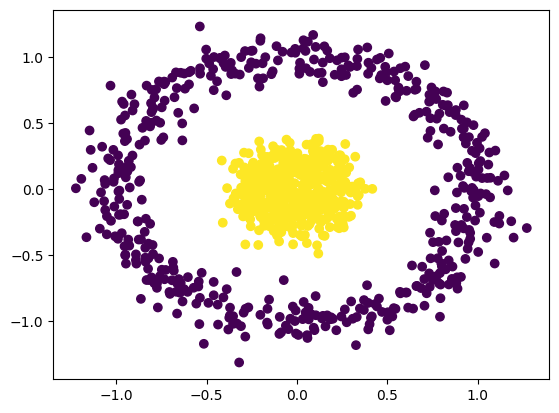

In [64]:
X, y = make_circles(n_samples=1000, noise=0.1, factor=0.2)
plt.scatter(X[:,0], X[:,1], c=y)
plt.show()

In [65]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).view(-1,1)
y_test = torch.tensor(y_test, dtype=torch.float32).view(-1,1)

if torch.cuda.is_available():
  device = torch.device("cuda")
else:
  device = torch.device("cpu")
print(device)

X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

cuda


In [66]:
class douglinhas(nn.Module):
  def __init__(self, hidden):
    super().__init__()
    self.layer1 = nn.Linear(2, hidden)
    self.layer2 = nn.Linear(hidden, 1)
  def forward(self, x):
    z = self.layer1(x)
    fz = torch.sigmoid(z)
    res = self.layer2(fz)
    return res
belo = douglinhas(hidden=3)
belo.to(device)

douglinhas(
  (layer1): Linear(in_features=2, out_features=3, bias=True)
  (layer2): Linear(in_features=3, out_features=1, bias=True)
)

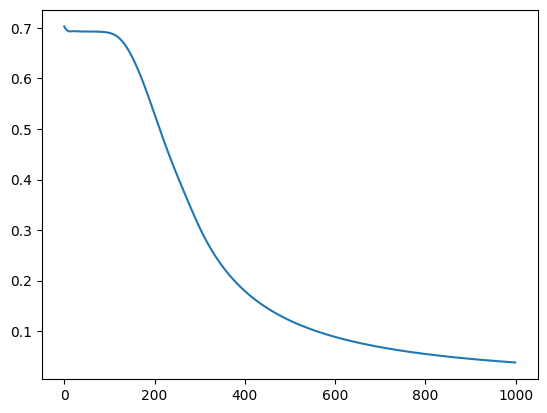

In [67]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(belo.parameters(), lr=0.01)
erro = []

for i in range(300):
  optimizer.zero_grad()
  preds = belo(X_train)
  loss = criterion(preds, y_train)
  loss.backward()
  optimizer.step()
  erro.append(loss.item())
plt.plot(erro)
plt.show()

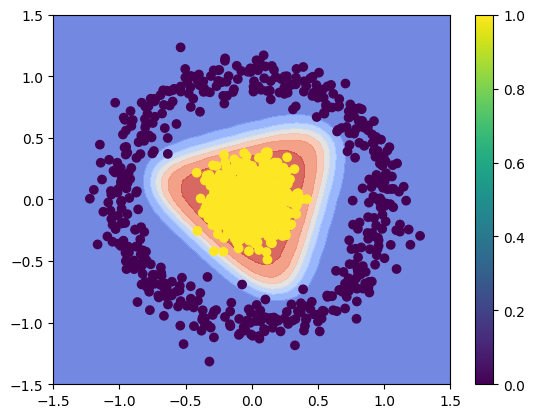

In [68]:
xx, yy = np.meshgrid(np.linspace(-1.5, 1.5, 50), np.linspace(-1.5, 1.5, 50))
grid = torch.tensor(np.c_[xx.ravel(),yy.ravel()], dtype=torch.float32).to(device)
with torch.no_grad():
  preds = torch.sigmoid(belo(grid)).cpu().numpy()
plt.contourf(xx, yy, preds.reshape(xx.shape), cmap="coolwarm", alpha=0.8)
plt.scatter(X[:,0], X[:,1], c=y)
plt.colorbar()
plt.show()